L'objet de ce projet est d'étudier des algorithmes de scoring aidant à la décision d'un accord de prêt. 

La finalité est d'utiliser des historiques de prêts et d'informations financières pour évaluer la probabilité de remboursement du prêt par le candidat. Les utilisateurs du modèle de scoring sont les chargés de relation client. Ils devront être capables de donner une justification concrête pour la non-attribution d'un prêt. 

Le modèle doit donc être facilement interprétable. 

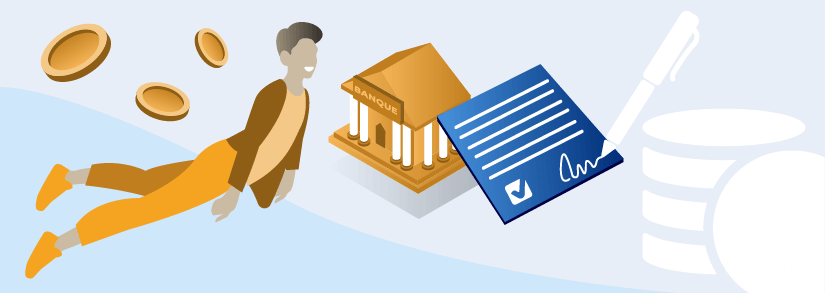

Ce notebook permet de tester plusieurs modèles et de les optimiser en variant certains de leurs hyperparamètres.
Les modèles évalués dans ce notebook sont :

- un modèle de référence KNN (K-nearest neighbors)
- un modèle linéaire de régression logistique
- un modèle linéaire de Machine à vecteurs de support (SVM)
- un modèle non linéaire d'arbre de décision
- un modèle non linéaire de Random Forest
- un modèle ensembliste Gradient Boosting Classifier
- un modèle ensembliste XGBClassifier
- un modèle ensembliste LightGBM Classifier
- un modèle de réseau de neurones MLP Classifier
- un modèle ensembliste Voting

Les critères sur lesquels ont été évalués les modèles sont les suivants :
- le temps de calcul
- les scores (sensibilité, precision, exactitude)
- le bénéfice supplémentaire par dollar investi

En fin de notebook, les différentes bases de données à notre disposition ont été évaluées pour permettre de sélectionner celle qui donnera les meilleures performances au modèle choisi.

# Préparation, visualisation et exploration des données

## Importation des données et des librairies

### Importation des librairies utiles au projet

In [1]:
# numpy and pandas pour la manipulation des données
import numpy as np
import pandas as pd
# matplotlib and seaborn pour les représentations graphiques
import matplotlib.pyplot as plt
import seaborn as sns

# File system management
import os

# Suppress warnings
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Les fonctions personnaliées
from fe_homecredit import *  # Importe le feature engineering pour la base de données du projet homecredit
from calcul_benefice import *  # Fonction de calcul des bénéfices
from my_functions import *

# Palette de couleur
a, b, c, d, e = [
    plt.cm.Blues, plt.cm.Oranges, plt.cm.Reds, plt.cm.Greens, plt.cm.Purples
]

Nous chargeons la base de données application_train nettoyée et complétée par de nouvelles variables.

In [3]:
df_nv = fe(0)
df_nv.replace([np.inf, -np.inf], np.nan, inplace=True)
df_nv = df_nv.fillna(0)

df = df_nv.sample(10000)

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées
df shape: (307506, 71)


# Application et comparaison des différents modèles

Pour pouvoir comparer les différents modèles, les données de performance de chacun sont stockées dans des variables.

In [4]:
modeles = []
time_calcul = []
recall_mdl = []
f_mdl = []
lr_auc_mdl = []
benef_tot_mdl = []
benef_p_cli_mdl = []
benef_p_dollar_mdl = []

## Le modèle KNN

temps de calcul : 2.0 sec
Matrice de confusion
il y a : 
 1384 Vrais Négatifs (le prêt a été remboursé) 
 444 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 107 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 65 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.93      0.76      0.83      1828
           1       0.13      0.38      0.19       172

    accuracy                           0.72      2000
   macro avg       0.53      0.57      0.51      2000
weighted avg       0.86      0.72      0.78      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475 k$
la somme perdue sans modèle est  92564.90100000001 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------------

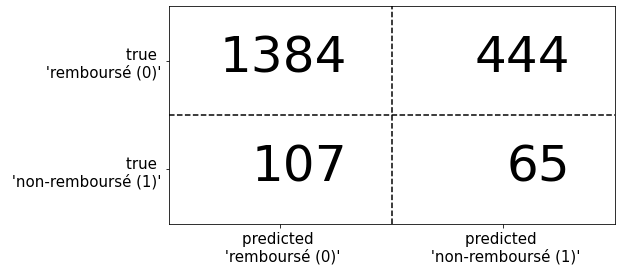

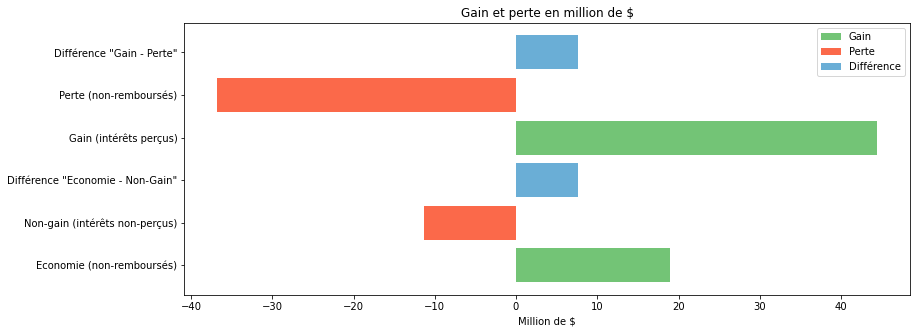

KNN: ROC AUC=0.617 Dummy: ROC AUC=0.489


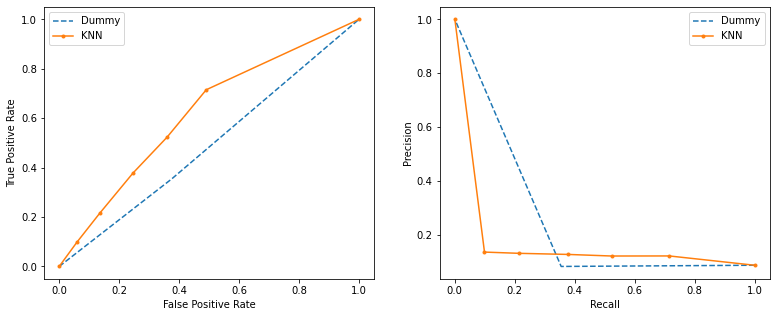

In [5]:
prediction, y_test, temps , lr_auc = knn(df)

In [6]:
b, edem, edol = benefice_somme(y_test, prediction,df)
modeles.append('KNN')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

## Regression linéaire

### Logistic Regression

La régression logistique permet de modéliser la probabilité que la demande de prêt d'un client appartienne à la classe "non-remboursé" (la classe positive, 'TARGET' = 1). Cette probabilité repose sur une transformation logistique d'une combinaison linéaire des variables.

A chaque variable est attribué un coefficient. Ces coefficients s'apprennent par maximisation de vraisemblance (ou du log de la vraisemblance).

temps de calcul : 3.0 sec
Matrice de confusion
il y a : 
 1492 Vrais Négatifs (le prêt a été remboursé) 
 336 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 92 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 80 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      1828
           1       0.19      0.47      0.27       172

    accuracy                           0.79      2000
   macro avg       0.57      0.64      0.57      2000
weighted avg       0.88      0.79      0.82      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
---------------------------------------

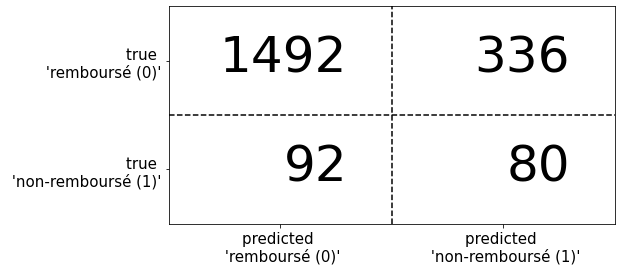

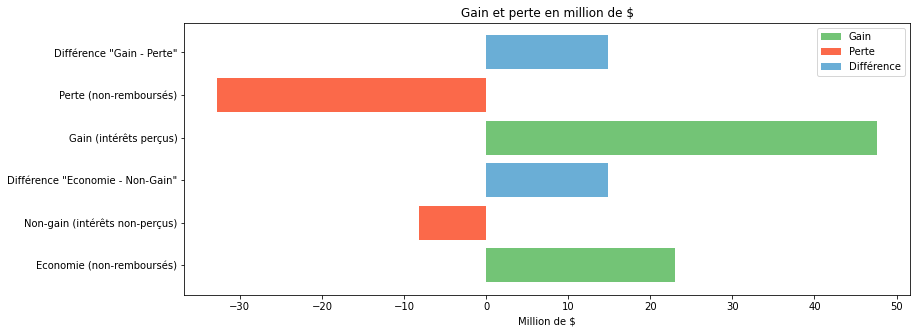

Logistic Regression : ROC AUC=0.730 Dummy: ROC AUC=0.498


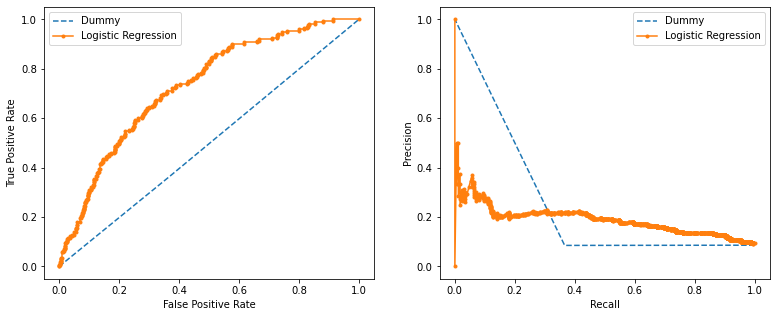

In [8]:
prediction, y_test, temps , lr_auc = logistic(df)

Plusieurs paramètres peuvent influencer la performance de la regression logistique.

D'abord, le paramètre C, qui est inversement proportionnel à la force de la régularisation.
Il est aussi possible de choisir le type de solveur (qui fournit une solution numérique au problème de maximisation de la vraisemblance). Par exemple, pour notre échantillon, le solveur 'liblinear' est plutôt judicieux. En effet, notre échantillon n'est pas imposant et notre objectif est de pouvoir focaliser les performances sur le débuscage des cible positive.
Enfin, les techniques de régularisation des modèles linéaires ℓ1 et ℓ2 s'appliquent aussi à la régression logistique. Ces régulateurs permettent d'éviter le surapprentissage. La norme ℓ1 permet d'obtenir un modèle parcimonieux alors que la norme ℓ2 pénalise le problème en réduisant le poids des variables.

Les paramètres C et ℓ1 vs ℓ2 vont être optimisés grâce à une grille de recherche (GridSearch)

In [10]:
grid_logistic(df)

Meilleur(s) hyperparamètre(s) sur le jeu d'entraînement:
{'C': 10.0, 'penalty': 'l1'}
Résultats de la validation croisée :
recall = 0.000 (+/-0.000) for {'C': 0.001, 'penalty': 'l1'}
recall = 0.000 (+/-0.000) for {'C': 0.001, 'penalty': 'l2'}
recall = 0.000 (+/-0.000) for {'C': 0.01, 'penalty': 'l1'}
recall = 0.002 (+/-0.006) for {'C': 0.01, 'penalty': 'l2'}
recall = 0.003 (+/-0.008) for {'C': 0.1, 'penalty': 'l1'}
recall = 0.008 (+/-0.000) for {'C': 0.1, 'penalty': 'l2'}
recall = 0.015 (+/-0.019) for {'C': 1.0, 'penalty': 'l1'}
recall = 0.015 (+/-0.019) for {'C': 1.0, 'penalty': 'l2'}
recall = 0.020 (+/-0.025) for {'C': 10.0, 'penalty': 'l1'}
recall = 0.020 (+/-0.025) for {'C': 10.0, 'penalty': 'l2'}
recall = 0.020 (+/-0.025) for {'C': 100.0, 'penalty': 'l1'}
recall = 0.020 (+/-0.025) for {'C': 100.0, 'penalty': 'l2'}
recall = 0.018 (+/-0.021) for {'C': 1000.0, 'penalty': 'l1'}
recall = 0.020 (+/-0.025) for {'C': 1000.0, 'penalty': 'l2'}

Sur le jeu de test : 0.000


temps de calcul : 0.3 sec
Matrice de confusion
il y a : 
 1492 Vrais Négatifs (le prêt a été remboursé) 
 336 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 92 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 80 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      1828
           1       0.19      0.47      0.27       172

    accuracy                           0.79      2000
   macro avg       0.57      0.64      0.57      2000
weighted avg       0.88      0.79      0.82      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
---------------------------------------

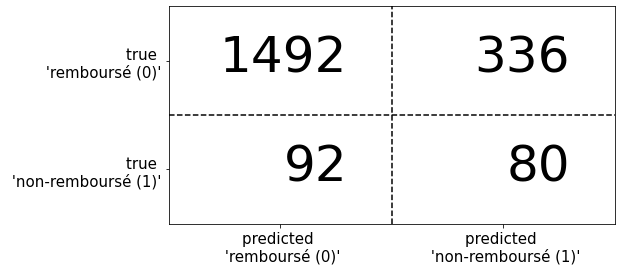

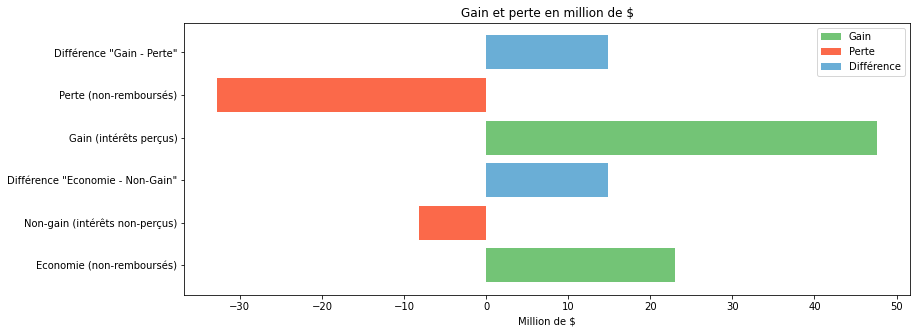

Logistic Regression : ROC AUC=0.730 Dummy : ROC AUC=0.488


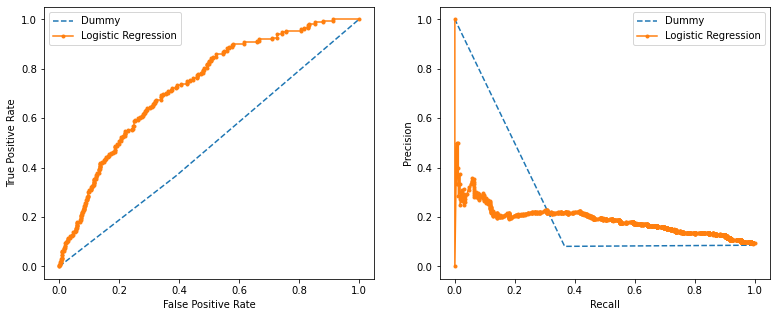

In [12]:
prediction, y_test, temps , lr_auc = logistic_opti(df)

In [13]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('Logistic Regression')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### SVM : Machines à Vecteurs de Support

Les SVM (Support Vector Machines) modélisent des hyperplans capables de séparer linéairement les données. Ces hyperplans sont situés prêts de points de jeu de données qui représentent les vecteurs de support. L'idée est de maximiser la distance (la marge) entre les hyperplans.

La sélection du kernel (noyau) 'rbf' permet de transformer notre problème (initialement non-linéaire) en problème linéaire pour obtenir un modèle plus performant (dans ce cas, notre SVM devient un modèle SVM à noyaux). Nos données sont redécrites dans un nouvel espace qui permet d'apprendre une fonction de décision linéaire.

Comme pour la regression logistique, plusieurs paramètres peuvent être optimiser grâce à GridSearch.

In [15]:
grid_svm(df)

Meilleur(s) hyperparamètre(s) sur le jeu d'entraînement:
{'C': 100.0}
Résultats de la validation croisée :
recall = 0.000 (+/-0.000) for {'C': 0.001}
recall = 0.000 (+/-0.000) for {'C': 0.01}
recall = 0.000 (+/-0.000) for {'C': 0.1}
recall = 0.000 (+/-0.000) for {'C': 1.0}
recall = 0.049 (+/-0.047) for {'C': 10.0}
recall = 0.091 (+/-0.079) for {'C': 100.0}
recall = 0.091 (+/-0.079) for {'C': 1000.0}

Sur le jeu de test : 0.140


temps de calcul : 34.2 sec
Matrice de confusion
il y a : 
 1685 Vrais Négatifs (le prêt a été remboursé) 
 143 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 138 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 34 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      1828
           1       0.19      0.20      0.19       172

    accuracy                           0.86      2000
   macro avg       0.56      0.56      0.56      2000
weighted avg       0.86      0.86      0.86      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
-------------------------------------------

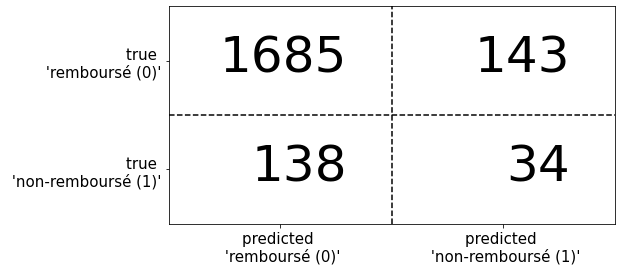

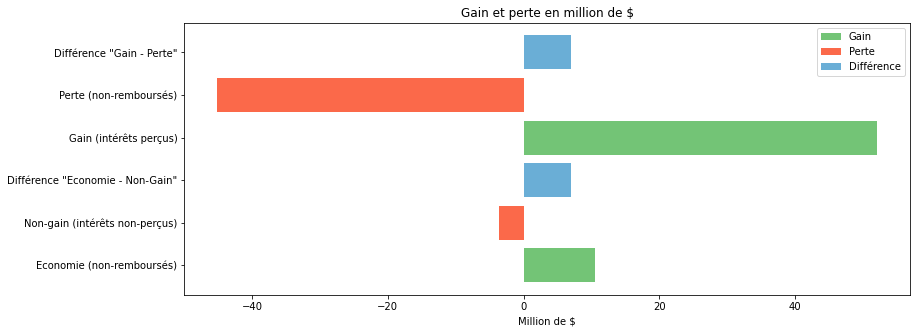

SVM : ROC AUC=0.655 Dummy : ROC AUC=0.487


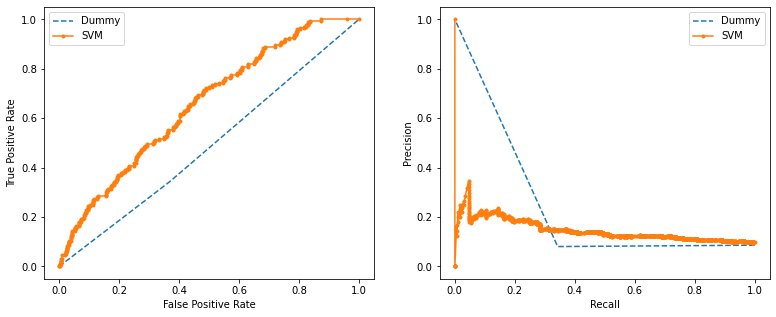

In [17]:
prediction, y_test, temps , lr_auc = svm_opti(df)

In [18]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('SVM')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

## Les modèles non-linéaires

### Arbre de décision

L'apprentissage par arbre de décision a pour but est de créer un modèle qui prédit la valeur de notre variable cible à partir de la valeur de plusieurs variables.

temps de calcul : 0.4 sec
Matrice de confusion
il y a : 
 1118 Vrais Négatifs (le prêt a été remboursé) 
 710 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 58 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 114 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.61      0.74      1828
           1       0.14      0.66      0.23       172

    accuracy                           0.62      2000
   macro avg       0.54      0.64      0.49      2000
weighted avg       0.88      0.62      0.70      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
--------------------------------------

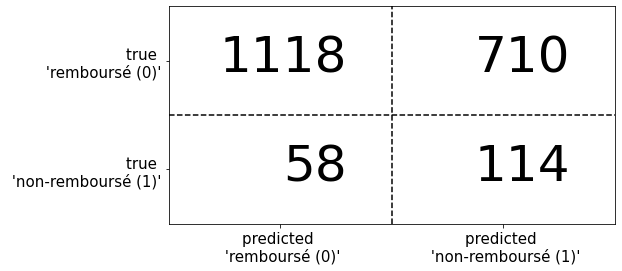

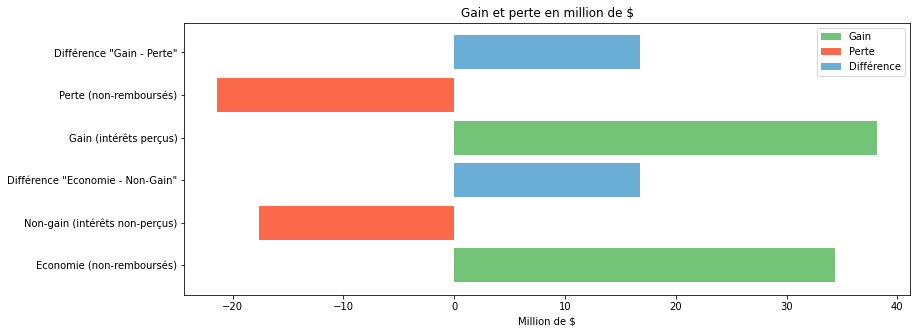

Arbre de décision : ROC AUC=0.677 Dummy : ROC AUC=0.526


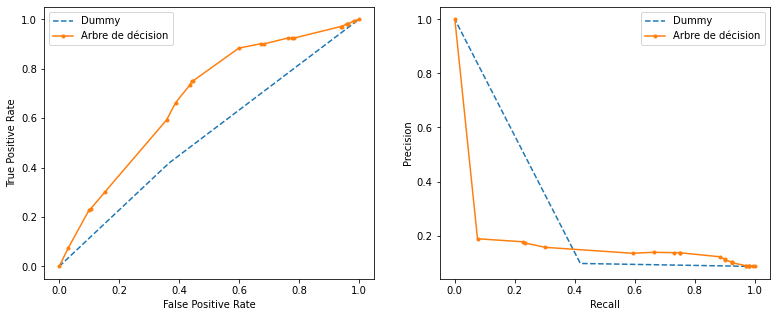

In [20]:
prediction, y_test, temps , lr_auc = add_(df)

In [21]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('Arbre de décision')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### Random Forest Classifier

L'algorithme Random Forest se base sur l'assemblage d'un variété d'arbres de décision.
Chaque arbre de décision est entraîné parallèlement aux autres et sur des groupes de données différents.
L'association des différents arbres obtenus permet de réduire la variance des prévisions d'un arbre de décision seul, améliorant ainsi leurs performances.

Il est intéressant de chercher à maximiser la performance du modèle en étudiant l'influence du nombre d'arbres de la forêt (n_estimators) et leur 'pronfondeur' (max_depth).

In [25]:
f1_Négatifs = []
f1_Positifs = []
recall = []
f1 = []

bene_somme_list = []
eco_dollar_list = []
eco_demandeur_list = []

for nd in range(1, 20, 1):
    prediction, y_test = rf_n_depth(df,nd)
    #print(nd)

    f=f1_score(y_test, prediction, average=None)
    f1_Négatifs.append(f[0])
    f1_Positifs.append(f[1])
    
    recall.append(recall_score(y_test, prediction))
    f1.append(f1_score(y_test, prediction))
    
    b, edem, edol = benefice_somme(y_test, prediction,df)
    
    bene_somme_list.append(b)
    eco_dollar_list.append(edol)
    eco_demandeur_list.append(edem)

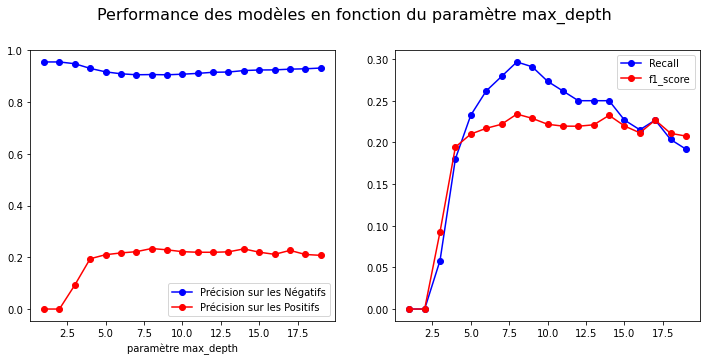

In [26]:
fig, (ax2, ax3) = plt.subplots(1, 2)
fig.suptitle('Performance des modèles en fonction du paramètre max_depth', size=16, y=1)
    
ax2.plot(range(1, 20, 1), f1_Négatifs, 'o-b')
ax2.plot(range(1, 20, 1), f1_Positifs, 'o-r')
ax2.legend(['Précision sur les Négatifs', 'Précision sur les Positifs'])
ax2.set_xlabel('paramètre max_depth')

ax3.plot(range(1, 20, 1), recall, 'o-b')
ax3.plot(range(1, 20, 1), f1, 'o-r')
ax3.legend(['Recall','f1_score'])
plt.show()

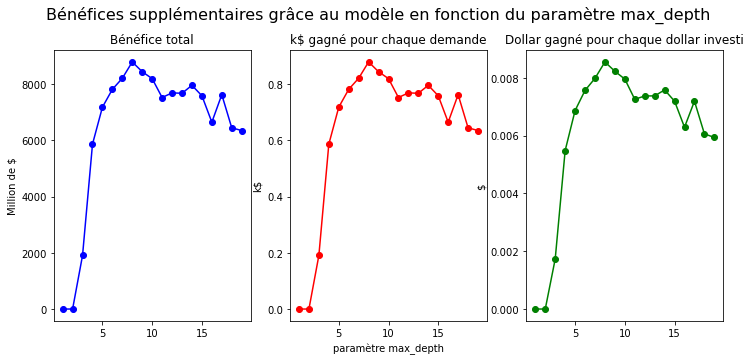

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Bénéfices supplémentaires grâce au modèle en fonction du paramètre max_depth'
            , size=16, y=1)    
    
plt.rcParams["figure.figsize"] = (14,4)    
ax1.plot(range(1, 20, 1), bene_somme_list, 'o-b')
ax1.set_title('Bénéfice total')
ax1.set_ylabel('Million de $')

ax2.plot(range(1, 20, 1), eco_demandeur_list, 'o-r')
ax2.set_title('k$ gagné pour chaque demande')
ax2.set_ylabel('k$')
ax2.set_xlabel('paramètre max_depth')

ax3.plot(range(1, 20, 1), eco_dollar_list, 'o-g')
ax3.set_title('Dollar gagné pour chaque dollar investi')
ax3.set_ylabel('$')

plt.show()

Le modèle commence à être performant pour un paramètre max_depth égal à 8.

In [28]:
prediction, y_test = rf_n_depth(df,8)

In [32]:
f1_Négatifs = []
f1_Positifs = []
recall = []
f1 = []

bene_somme_list = []
eco_dollar_list = []
eco_demandeur_list = []

for n_e in range(50, 600, 50):
    prediction, y_test = rf_n_est(df,n_e)
    #print(n_e)

    f=f1_score(y_test, prediction, average=None)
    f1_Négatifs.append(f[0])
    f1_Positifs.append(f[1])
    
    recall.append(recall_score(y_test, prediction))
    f1.append(f1_score(y_test, prediction))
    
    b, edem, edol = benefice_somme(y_test, prediction,df)
    
    bene_somme_list.append(b)
    eco_dollar_list.append(edol)
    eco_demandeur_list.append(edem)

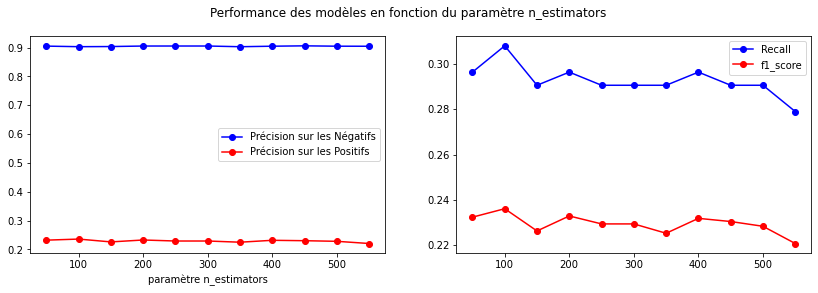

In [33]:
fig, (ax2, ax3) = plt.subplots(1, 2)
fig.suptitle('Performance des modèles en fonction du paramètre n_estimators')
    
ax2.plot(range(50, 600, 50), f1_Négatifs, 'o-b')
ax2.plot(range(50, 600, 50), f1_Positifs, 'o-r')
ax2.legend(['Précision sur les Négatifs', 'Précision sur les Positifs'])
ax2.set_xlabel('paramètre n_estimators')

ax3.plot(range(50, 600, 50), recall, 'o-b')
ax3.plot(range(50, 600, 50), f1, 'o-r')
ax3.legend(['Recall','f1_score'])
plt.show()

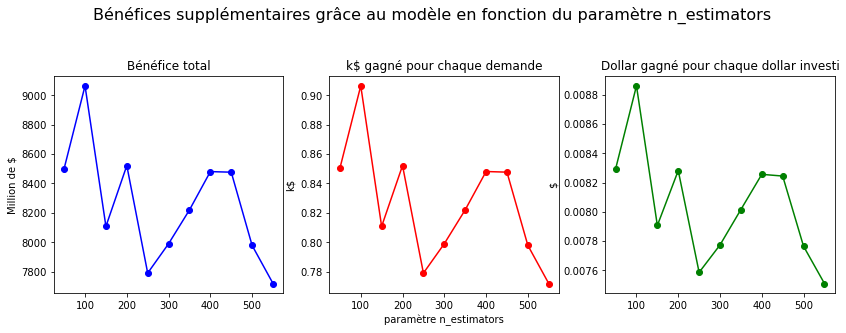

In [34]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Bénéfices supplémentaires grâce au modèle en fonction du paramètre n_estimators'
            , size=16, y=1.12)    
    
plt.rcParams["figure.figsize"] = (14,4)    
ax1.plot(range(50, 600, 50), bene_somme_list, 'o-b')
ax1.set_title('Bénéfice total')
ax1.set_ylabel('Million de $')

ax2.plot(range(50, 600, 50), eco_demandeur_list, 'o-r')
ax2.set_title('k$ gagné pour chaque demande')
ax2.set_ylabel('k$')
ax2.set_xlabel('paramètre n_estimators')

ax3.plot(range(50, 600, 50), eco_dollar_list, 'o-g')
ax3.set_title('Dollar gagné pour chaque dollar investi')
ax3.set_ylabel('$')

plt.show()

Le modèle a un bénéfice intéressant à partir de n_estimators = 100

In [35]:
prediction, y_test = rf_n_est(df,100)

temps de calcul : 3.7 sec
Matrice de confusion
il y a : 
 1609 Vrais Négatifs (le prêt a été remboursé) 
 219 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 119 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 53 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.93      0.88      0.90      1828
           1       0.19      0.31      0.24       172

    accuracy                           0.83      2000
   macro avg       0.56      0.59      0.57      2000
weighted avg       0.87      0.83      0.85      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
--------------------------------------------

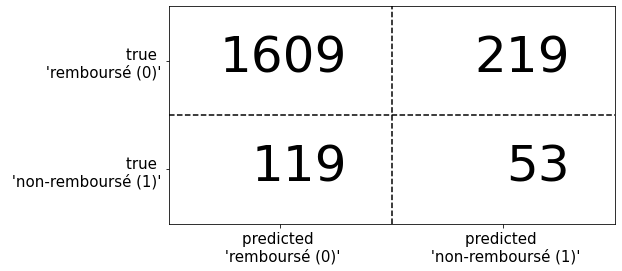

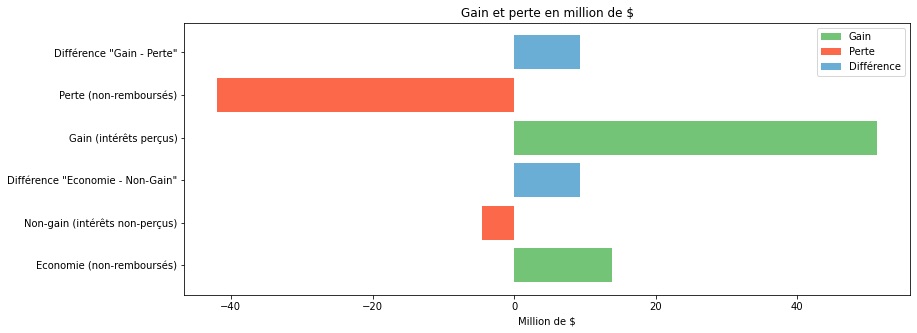

Random Forest : ROC AUC=0.716 Dummy : ROC AUC=0.532


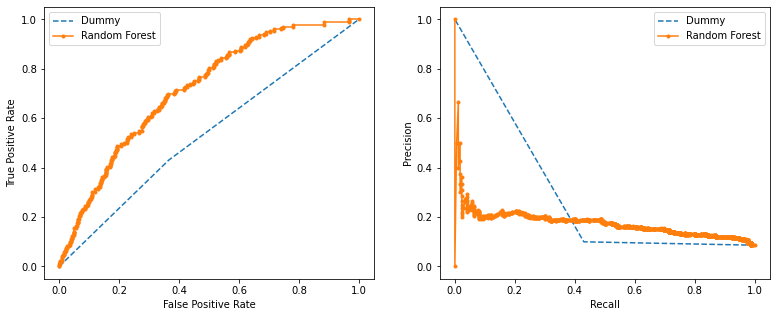

In [37]:
prediction, y_test, temps , lr_auc = rf_opti(df)

In [38]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('Random Forest')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### Gradient Boosting Classifier

L’algorithme Gradient Boosting Classifier est un cas particulier du Boosting. Le Boosting utilise plusieurs modèles pour les aggréger et obtenir un seul résultat final. La construction du modèle se fait de manière séquentielle. Un premier modèle est évaluer par l'algorithme. Cette évaluation engendre une pondération de chacun de nos clients en fonction de la performance de la prédiction obtenue.
L'idée générale est de donner beaucoup de poids aux clients dont la prédiction de la valeur cible est erronée. Cette pondération s'applique pour la construction du modèle suivant. Au fur et à mesure de la construction eds modèles, le poids est corrigé pour les clients dont la cible est difficile à prédire. Ceci permet petit à petit de prédire la classe des données très difficiles à classer au départ.

#### Détermination du nombre optimal de n_estimators

In [40]:
f1_Négatifs = []
f1_Positifs = []
recall = []
f1 = []

bene_somme_list = []
eco_dollar_list = []
eco_demandeur_list = []

for n_e in range(50, 600, 50):
    prediction, y_test = gb_n_e(df,n_e)
    #print(n_e)

    f=f1_score(y_test, prediction, average=None)
    f1_Négatifs.append(f[0])
    f1_Positifs.append(f[1])
    
    recall.append(recall_score(y_test, prediction))
    f1.append(f1_score(y_test, prediction))
    
    b, edem, edol = benefice_somme(y_test, prediction,df)
    
    bene_somme_list.append(b)
    eco_dollar_list.append(edol)
    eco_demandeur_list.append(edem)

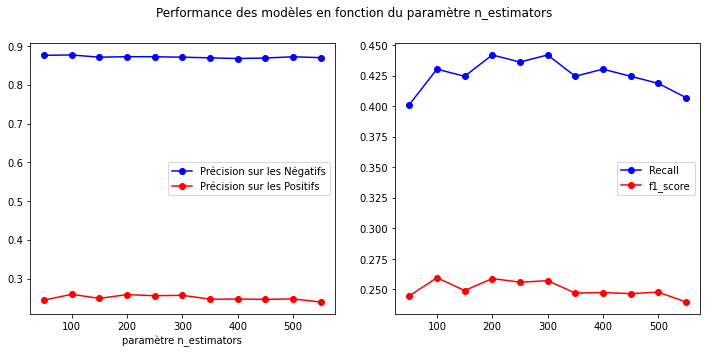

In [41]:
fig, (ax2, ax3) = plt.subplots(1, 2)
fig.suptitle('Performance des modèles en fonction du paramètre n_estimators')
    
ax2.plot(range(50, 600, 50), f1_Négatifs, 'o-b')
ax2.plot(range(50, 600, 50), f1_Positifs, 'o-r')
ax2.legend(['Précision sur les Négatifs', 'Précision sur les Positifs'])
ax2.set_xlabel('paramètre n_estimators')

ax3.plot(range(50, 600, 50), recall, 'o-b')
ax3.plot(range(50, 600, 50), f1, 'o-r')
ax3.legend(['Recall','f1_score'])
plt.show()

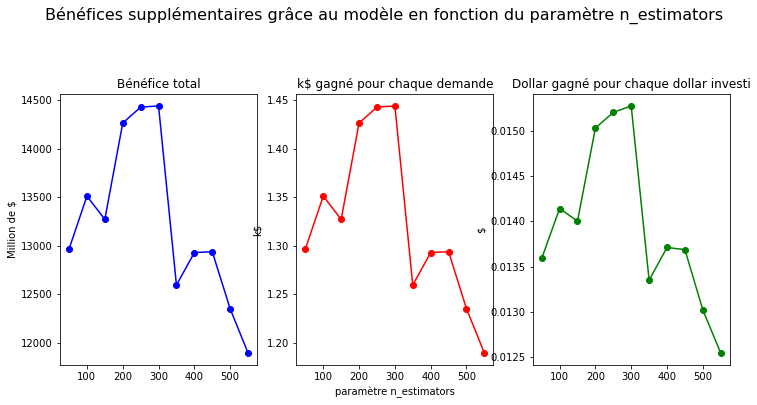

In [42]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Bénéfices supplémentaires grâce au modèle en fonction du paramètre n_estimators'
            , size=16, y=1.12)    
    
plt.rcParams["figure.figsize"] = (14,4)    
ax1.plot(range(50, 600, 50), bene_somme_list, 'o-b')
ax1.set_title('Bénéfice total')
ax1.set_ylabel('Million de $')

ax2.plot(range(50, 600, 50), eco_demandeur_list, 'o-r')
ax2.set_title('k$ gagné pour chaque demande')
ax2.set_ylabel('k$')
ax2.set_xlabel('paramètre n_estimators')

ax3.plot(range(50, 600, 50), eco_dollar_list, 'o-g')
ax3.set_title('Dollar gagné pour chaque dollar investi')
ax3.set_ylabel('$')

plt.show()

Le nombre n_estimators semble être optimal pour une valeur de 200.

#### Détermination de la valeur optimale pour learning_rate

In [44]:
f1_Négatifs = []
f1_Positifs = []
recall = []
f1 = []

bene_somme_list = []
eco_dollar_list = []
eco_demandeur_list = []

for l_r in range(1, 21, 2):
    l_r=l_r/10
    prediction, y_test = gb_l_r(df,l_r)
    #print(l_r)

    f=f1_score(y_test, prediction, average=None)
    f1_Négatifs.append(f[0])
    f1_Positifs.append(f[1])
    
    recall.append(recall_score(y_test, prediction))
    f1.append(f1_score(y_test, prediction))
    
    b, edem, edol = benefice_somme(y_test, prediction,df)
    
    bene_somme_list.append(b)
    eco_dollar_list.append(edol)
    eco_demandeur_list.append(edem)

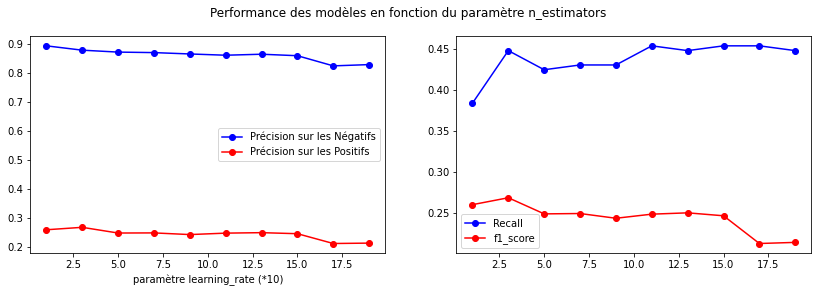

In [45]:
fig, (ax2, ax3) = plt.subplots(1, 2)
fig.suptitle('Performance des modèles en fonction du paramètre n_estimators')
    
ax2.plot(range(1, 21, 2), f1_Négatifs, 'o-b')
ax2.plot(range(1, 21, 2), f1_Positifs, 'o-r')
ax2.legend(['Précision sur les Négatifs', 'Précision sur les Positifs'])
ax2.set_xlabel('paramètre learning_rate (*10)')

ax3.plot(range(1, 21, 2), recall, 'o-b')
ax3.plot(range(1, 21, 2), f1, 'o-r')
ax3.legend(['Recall','f1_score'])
plt.show()

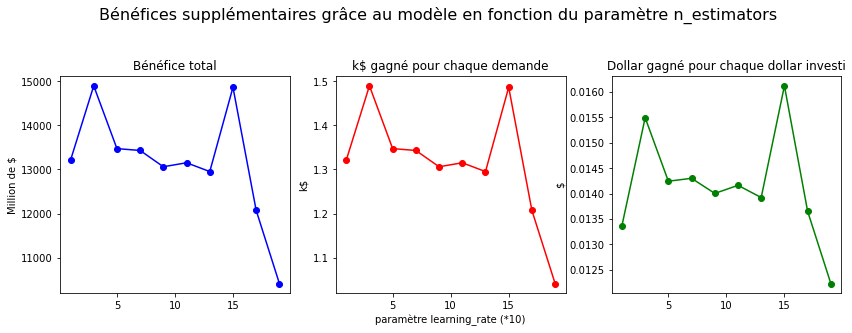

In [46]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Bénéfices supplémentaires grâce au modèle en fonction du paramètre n_estimators'
            , size=16, y=1.12)    
    
plt.rcParams["figure.figsize"] = (14,4)    
ax1.plot(range(1, 21, 2), bene_somme_list, 'o-b')
ax1.set_title('Bénéfice total')
ax1.set_ylabel('Million de $')

ax2.plot(range(1, 21, 2), eco_demandeur_list, 'o-r')
ax2.set_title('k$ gagné pour chaque demande')
ax2.set_ylabel('k$')
ax2.set_xlabel('paramètre learning_rate (*10)')

ax3.plot(range(1, 21, 2), eco_dollar_list, 'o-g')
ax3.set_title('Dollar gagné pour chaque dollar investi')
ax3.set_ylabel('$')

plt.show()

La valeur pour learning_rate semble être optimale à 0.4.

temps de calcul : 4.2 sec
Matrice de confusion
il y a : 
 1491 Vrais Négatifs (le prêt a été remboursé) 
 337 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 99 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 73 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      1828
           1       0.18      0.42      0.25       172

    accuracy                           0.78      2000
   macro avg       0.56      0.62      0.56      2000
weighted avg       0.87      0.78      0.82      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.90099999998 k$
le bénéfice sans modèle est  -36834.0 k$
-------------------------------

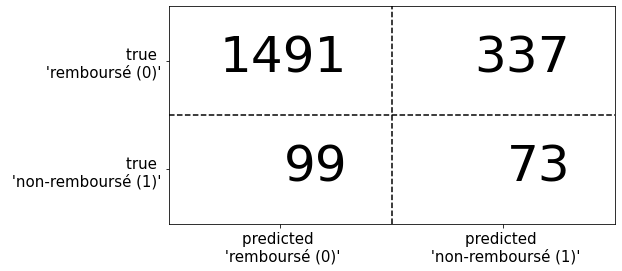

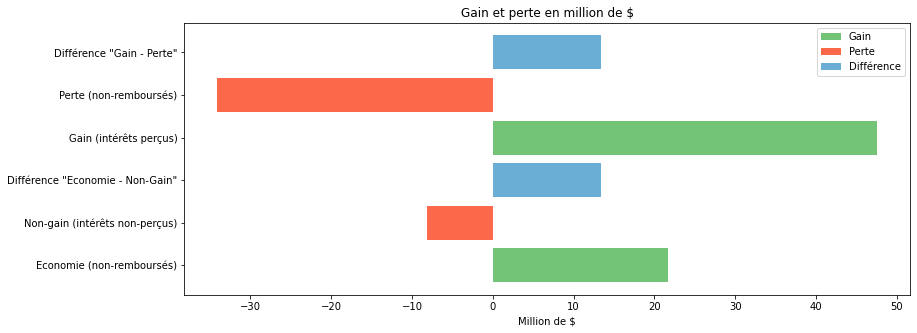

Gradient Boosting Classifier : ROC AUC=0.725 Dummy : ROC AUC=0.488


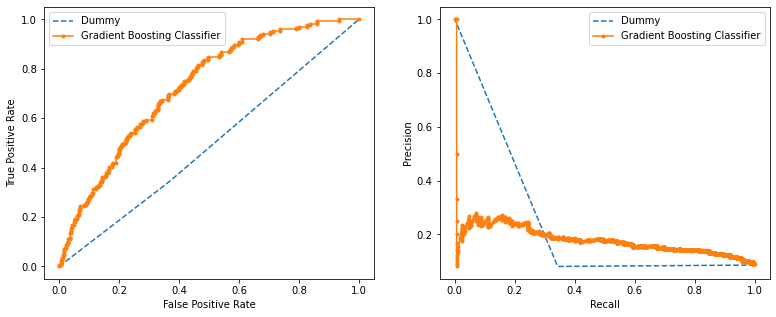

In [48]:
prediction, y_test, temps , lr_auc = gb_opti(df)

In [49]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('Gradient Boosting Classifier')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### XGBClassifier

L'algorithme XGBoost (eXtreme Gradient Boosting) est basé sur un algorithme d'arbres de décision boostés par gradient. 

Cette méthode utilise une meilleure meilleure technique de régularisation pour réduire le surapprentissage par rapport au simple Boosting par gradient.

Là encore, plusieurs hyperparamètres sont à optimiser.

[14:43:02] WARNING: C:/Users/Administrator/workspace/xgboost-win64_release_1.4.0/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
temps de calcul : 8.5 sec
Matrice de confusion
il y a : 
 1519 Vrais Négatifs (le prêt a été remboursé) 
 309 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 103 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 69 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.83      0.88      1828
           1       0.18      0.40      0.25       172

    accuracy                           0.79      2000
   macro avg       0.56      0.62      0.57      2000
weighted avg       0.

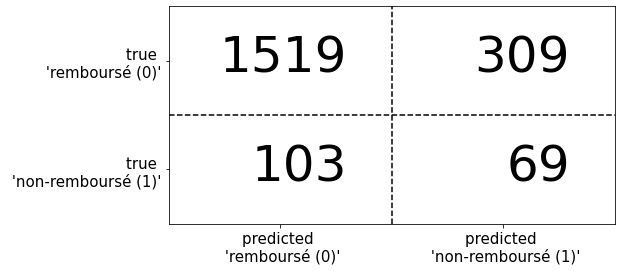

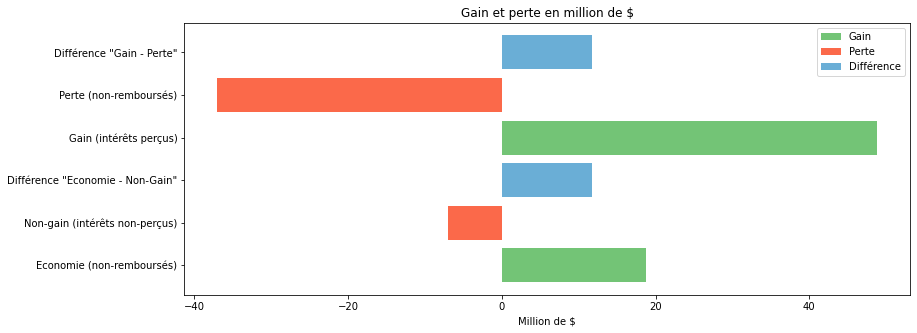

XGBClassifier : ROC AUC=0.722 Dummy : ROC AUC=0.512


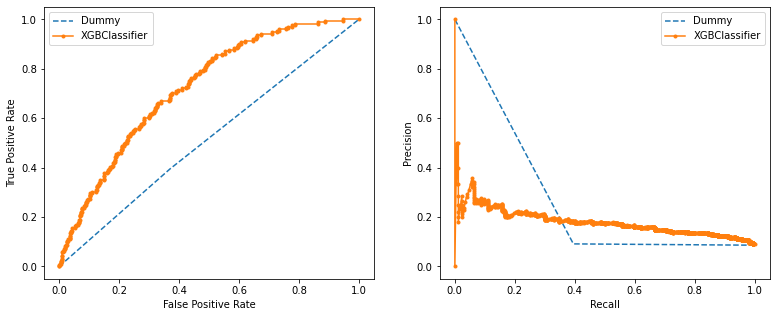

In [51]:
prediction, y_test, temps , lr_auc = xgb_opti(df)

In [52]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('XGBClassifier')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### LightGBM Classifier

L'algorithme LightGBM Classifier est aussi un algorithme qui repose sur la tecjnoque de Boosting.

temps de calcul : 2.1 sec
Matrice de confusion
il y a : 
 1549 Vrais Négatifs (le prêt a été remboursé) 
 279 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 107 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 65 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.85      0.89      1828
           1       0.19      0.38      0.25       172

    accuracy                           0.81      2000
   macro avg       0.56      0.61      0.57      2000
weighted avg       0.87      0.81      0.83      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.90100000001 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------

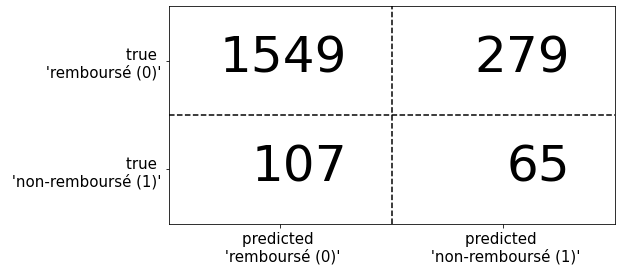

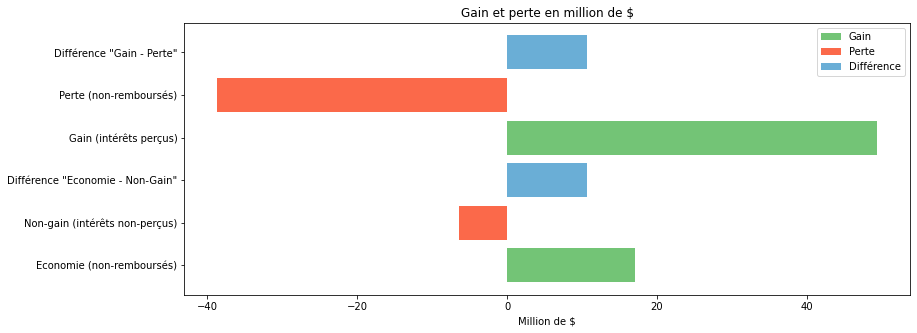

LGBMClassifier : ROC AUC=0.714 Dummy : ROC AUC=0.525


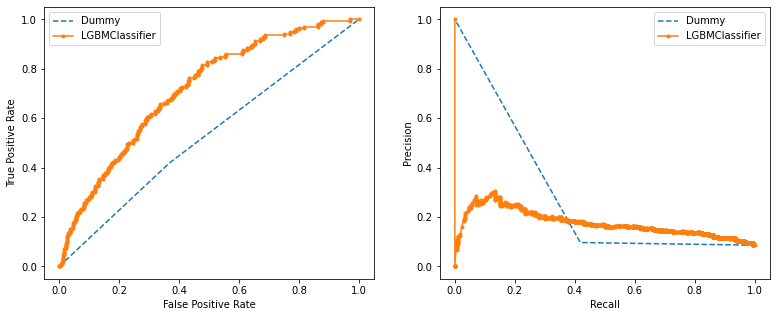

In [54]:
prediction, y_test, temps , lr_auc = lgbm_opti(df)

In [55]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('LGBMClassifier')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### MLP Classifier

L'algorithme MLP Classifier est basé sur le principe du perceptron, qui est un neurone artificiel. Ce perceptron est l'un des rouages des réseaux de neurones, faisant passer l'algorithme dans le domaine du Deep Learning. Le perceptron est simplement une fonction mathématique. Sa construction se base sur le modèle des neurones biologiques. En effet, chaque perceptron reçoit una certain nombre de données. Il les examine, effectue des calculs et donne un résultat. Ce résultat est issu d'une fonction non-linéaire. Il permet ainsi l'apprentissage de modèles paramètriques qui sont construits à partir d'une combinaison linéaire de variable.

Grâce au perceptron, il est possible de construire un modèle avec un apprentissage basé sur des modèles de regression, de classification (binaire ou multiclasse). Dans notre cas, nous sommes dans le cas d'une fonction logistique (activation = 'logistic').

Au fur et à mesure de la construction du modèle, les poids sur les différentes variables sont ajustés grâce à la technique du gradient. L'empilement des neurones en réseau de neurones permet de modéliser des fonctions mathématiques complexes. 

temps de calcul : 3.4 sec
Matrice de confusion
il y a : 
 1480 Vrais Négatifs (le prêt a été remboursé) 
 348 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 85 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 87 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.81      0.87      1828
           1       0.20      0.51      0.29       172

    accuracy                           0.78      2000
   macro avg       0.57      0.66      0.58      2000
weighted avg       0.88      0.78      0.82      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.32347500001 k$
la somme perdue sans modèle est  92564.90100000001 k$
le bénéfice sans modèle est  -36834.0 k$
--------------------------------

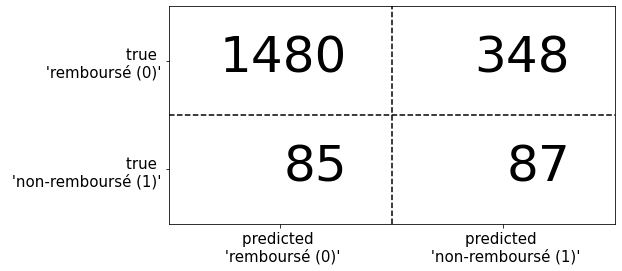

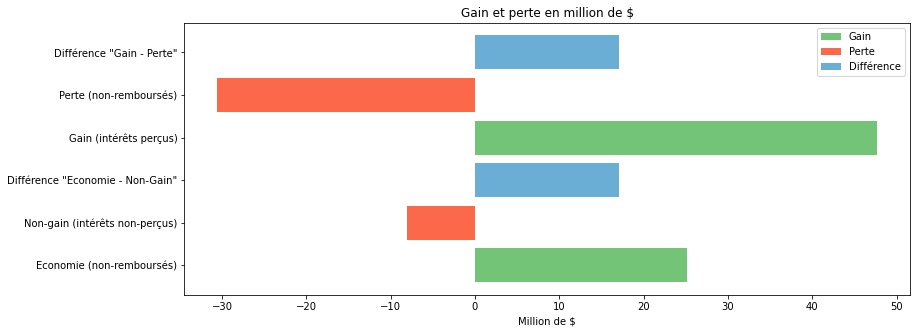

MLPClassifier : ROC AUC=0.729 Dummy : ROC AUC=0.488


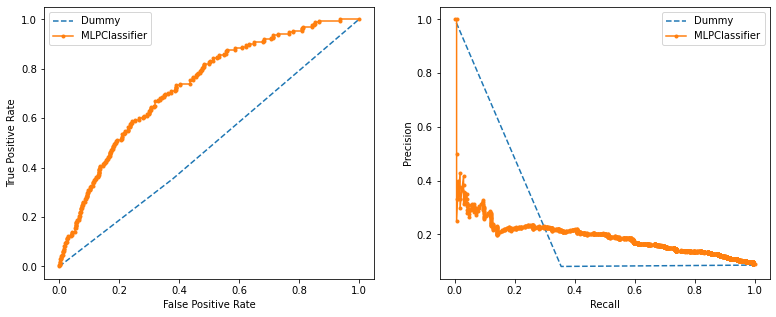

In [57]:
prediction, y_test, temps , lr_auc = mlp_opti(df)

In [58]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('MLPClassifier')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

### Voting

Pipeline 0.786
recall : 0.46511627906976744
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      1828
           1       0.19      0.47      0.27       172

    accuracy                           0.79      2000
   macro avg       0.57      0.64      0.57      2000
weighted avg       0.88      0.79      0.82      2000

Matrice de confusion
il y a : 
 1492 Vrais Négatifs (le prêt a été remboursé) 
 336 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 92 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 80 Vrais Positifs (le prêt n'a pas été remboursé) 



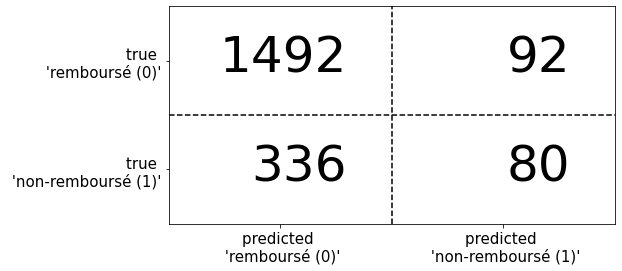

la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  55731.323475000005 k$
le bénéfice sans modèle est  0.0 k$
------------------------------------------------------------------------------------------
Grâce à ce modèle, la banque fait une économie de  1.0 k$ par client
Grâce à ce modèle, la banque fait une économie de  1.0 k$ pour chaque dollar gagné
------------------------------------------------------------------------------------------
la somme gagnée avec modèle est  47601.296775 k$
la somme perdue avec modèle est  32739.0 k$
le bénéfice avec modèle est  14863.0 k$


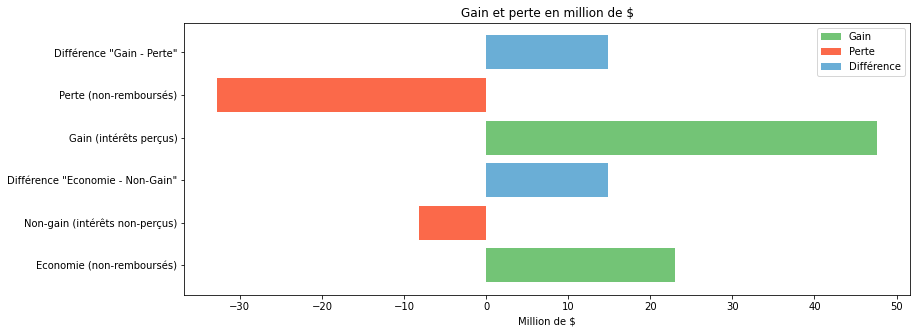

Pipeline 0.782
recall : 0.43023255813953487
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      1828
           1       0.18      0.43      0.25       172

    accuracy                           0.78      2000
   macro avg       0.56      0.62      0.56      2000
weighted avg       0.87      0.78      0.82      2000

Matrice de confusion
il y a : 
 1490 Vrais Négatifs (le prêt a été remboursé) 
 338 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 98 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 74 Vrais Positifs (le prêt n'a pas été remboursé) 



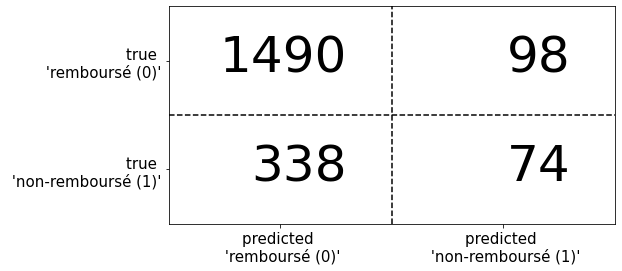

la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  55731.323475000005 k$
le bénéfice sans modèle est  0.0 k$
------------------------------------------------------------------------------------------
Grâce à ce modèle, la banque fait une économie de  1.0 k$ par client
Grâce à ce modèle, la banque fait une économie de  1.0 k$ pour chaque dollar gagné
------------------------------------------------------------------------------------------
la somme gagnée avec modèle est  47462.338575 k$
la somme perdue avec modèle est  33083.0 k$
le bénéfice avec modèle est  14379.0 k$


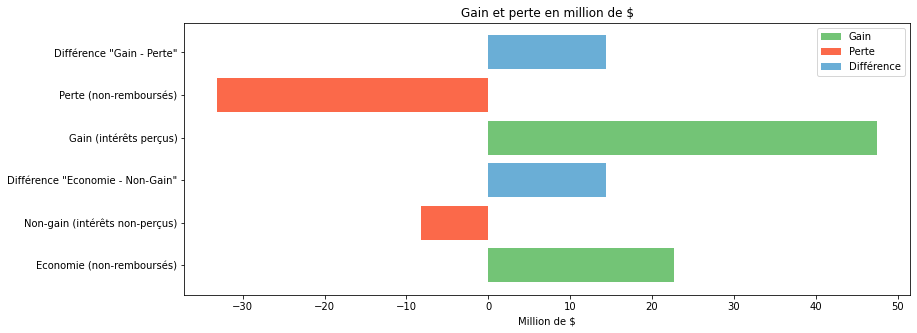

Pipeline 0.783
recall : 0.5058139534883721
              precision    recall  f1-score   support

           0       0.95      0.81      0.87      1828
           1       0.20      0.51      0.29       172

    accuracy                           0.78      2000
   macro avg       0.57      0.66      0.58      2000
weighted avg       0.88      0.78      0.82      2000

Matrice de confusion
il y a : 
 1479 Vrais Négatifs (le prêt a été remboursé) 
 349 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 85 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 87 Vrais Positifs (le prêt n'a pas été remboursé) 



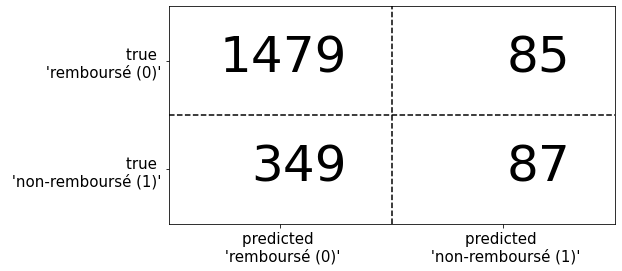

la somme gagnée sans modèle est  55731.32347500001 k$
la somme perdue sans modèle est  92564.90100000001 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.32347500001 k$
la somme perdue sans modèle est  55731.32347500001 k$
le bénéfice sans modèle est  0.0 k$
------------------------------------------------------------------------------------------
Grâce à ce modèle, la banque fait une économie de  2.0 k$ par client
Grâce à ce modèle, la banque fait une économie de  1.0 k$ pour chaque dollar gagné
------------------------------------------------------------------------------------------
la somme gagnée avec modèle est  47625.52545000001 k$
la somme perdue avec modèle est  30544.0 k$
le bénéfice avec modèle est  17081.0 k$


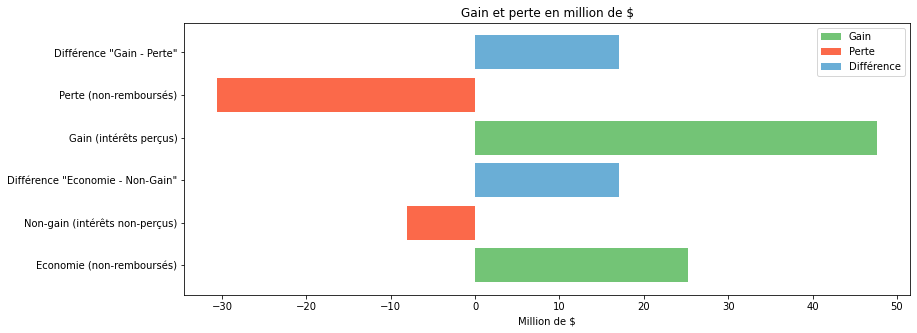

VotingClassifier 0.7845
recall : 0.4883720930232558
              precision    recall  f1-score   support

           0       0.94      0.81      0.87      1828
           1       0.20      0.49      0.28       172

    accuracy                           0.78      2000
   macro avg       0.57      0.65      0.58      2000
weighted avg       0.88      0.78      0.82      2000

Matrice de confusion
il y a : 
 1485 Vrais Négatifs (le prêt a été remboursé) 
 343 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 88 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 84 Vrais Positifs (le prêt n'a pas été remboursé) 



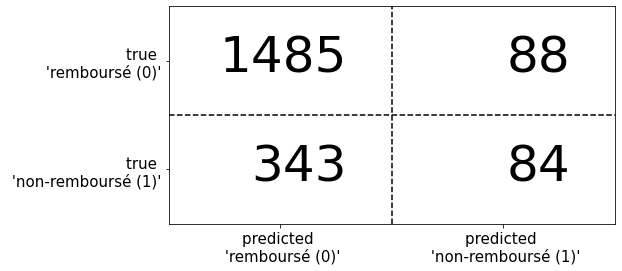

la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.90100000001 k$
le bénéfice sans modèle est  -36834.0 k$
------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  55731.323475 k$
le bénéfice sans modèle est  7.275957614183426e-12 k$
------------------------------------------------------------------------------------------
Grâce à ce modèle, la banque fait une économie de  2.0 k$ par client
Grâce à ce modèle, la banque fait une économie de  1.0 k$ pour chaque dollar gagné
------------------------------------------------------------------------------------------
la somme gagnée avec modèle est  47609.32950000001 k$
la somme perdue avec modèle est  31399.0 k$
le bénéfice avec modèle est  16211.0 k$


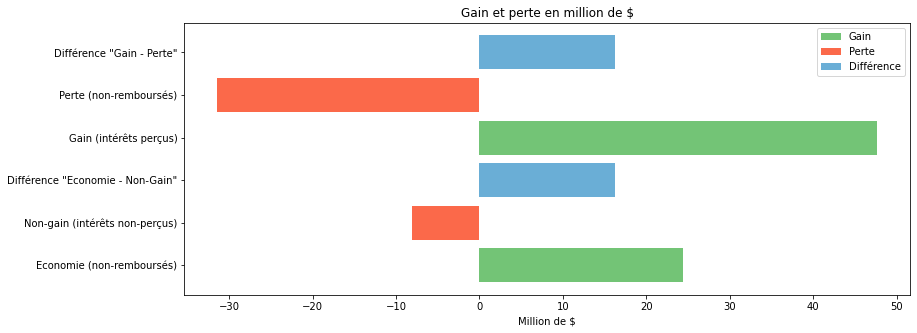

In [60]:
choix_Class(df)

temps de calcul : 7.0 sec
Matrice de confusion
il y a : 
 1502 Vrais Négatifs (le prêt a été remboursé) 
 326 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 95 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 77 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.82      0.88      1828
           1       0.19      0.45      0.27       172

    accuracy                           0.79      2000
   macro avg       0.57      0.63      0.57      2000
weighted avg       0.88      0.79      0.82      2000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  55731.323475000005 k$
la somme perdue sans modèle est  92564.901 k$
le bénéfice sans modèle est  -36834.0 k$
---------------------------------------

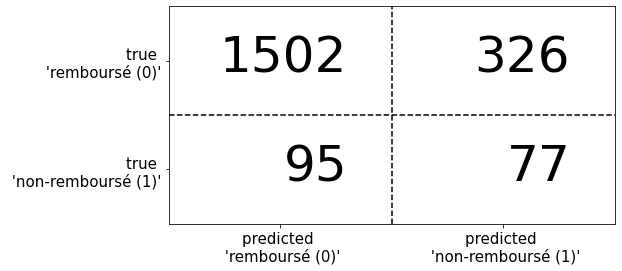

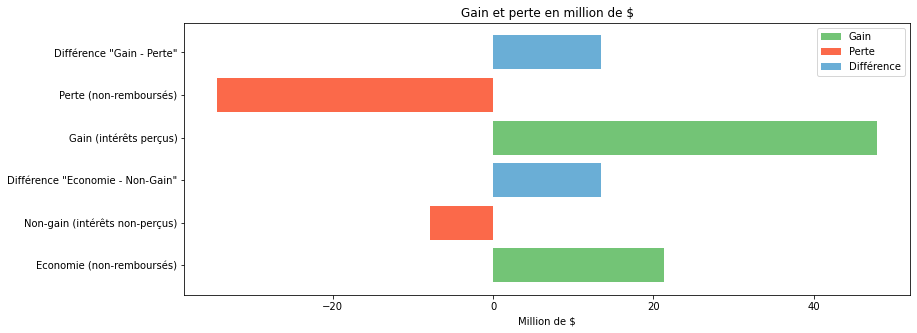

Gradient Boosting Classifier : ROC AUC=0.732 Dummy : ROC AUC=0.508


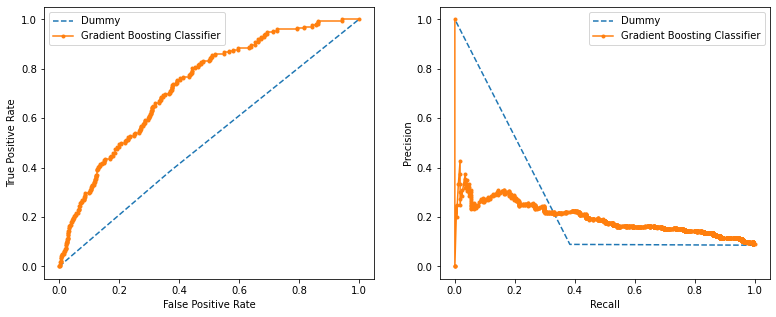

In [62]:
prediction, y_test, temps , lr_auc = best_voting(df)

In [63]:
b, edem, edol = benefice_somme(y_test, prediction,df)

modeles.append('Voting')
time_calcul.append(temps)
benef_tot_mdl.append(round(b,2))
benef_p_cli_mdl.append(round(edem,2))
benef_p_dollar_mdl.append(round(edol,2))
recall_mdl.append(round(recall_score(y_test, prediction),2))
f_mdl.append(round(f1_score(y_test, prediction),2))
lr_auc_mdl.append(round(lr_auc,2))

## Comparaison des différents modèles

In [64]:
comp = {'modeles': modeles, 'temps de calcul': time_calcul,
    'recall': recall_mdl, 'mesure f1': f_mdl, 'roc auc': lr_auc_mdl,
    'benefice total (en k$)': benef_tot_mdl , 'benefice par demande (en $)': benef_p_cli_mdl, 
     'benefice par dollar (en $)': benef_p_dollar_mdl }
comparaison = pd.DataFrame(comp)

In [65]:
comparaison = comparaison.drop([comparaison.index[6]])

In [66]:
comparaison

,modeles,temps de calcul,recall,mesure f1,roc auc,benefice total (en k$),benefice par demande (en $),benefice par dollar (en $)
0,KNN,2.0,0.38,0.19,0.16,7652.0,0.77,0.01
1,Logistic Regression,0.3,0.47,0.27,0.19,14863.0,1.49,0.02
2,SVM,34.2,0.20,0.19,0.15,6955.0,0.70,0.01
3,Arbre de décision,0.4,0.66,0.23,0.18,16783.0,1.68,0.02
4,Random Forest,3.7,0.31,0.24,0.17,9326.0,0.93,0.01
5,Gradient Boosting Classifier,4.2,0.42,0.25,0.18,13452.0,1.35,0.01
7,LGBMClassifier,2.1,0.38,0.25,0.17,10689.0,1.07,0.01
8,MLPClassifier,3.4,0.51,0.29,0.20,17104.0,1.71,0.02
9,Voting,7.0,0.45,0.27,0.19,13474.0,1.35,0.01


Finalement, le meilleur modèle est celui de l'arbre de décision.
En terme de modèles linéaires, le modèle de régression logistiques est bien meilleur tant au niveau des bénéfices supplémentaires qu'au niveau de temps de calcul.

Le modèle du Voting n'est finalement pas pertinent car il n'améliore pas plus que ça les performances et est bien plus lents que d'autres modèles plus performants.

# Influence des tailles d'échantillons et des différentes bases de données utilisées

## Effet de la taille de l'échantillon

In [68]:
f1_Négatifs = []
f1_Positifs = []
recall = []
f1 = []

bene_somme_list = []
eco_dollar_list = []
eco_demandeur_list = []

for samp in range(10000, 100000, 10000):
    #print('Sample : ', samp )
    dfsample = df_nv.sample(samp)
    prediction, y_test = add_simple(dfsample)

    f=f1_score(y_test, prediction, average=None)
    f1_Négatifs.append(f[0])
    f1_Positifs.append(f[1])
    
    recall.append(recall_score(y_test, prediction))
    f1.append(f1_score(y_test, prediction))
    
    b, edem, edol = benefice_somme(y_test, prediction,dfsample)
    
    bene_somme_list.append(b)
    eco_dollar_list.append(edol)
    eco_demandeur_list.append(edem)

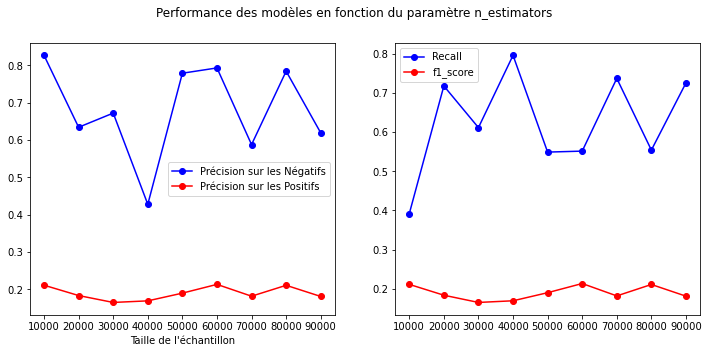

In [69]:
fig, (ax2, ax3) = plt.subplots(1, 2)
fig.suptitle('Performance des modèles en fonction du paramètre n_estimators')
    
ax2.plot(range(10000, 100000, 10000), f1_Négatifs, 'o-b')
ax2.plot(range(10000, 100000, 10000), f1_Positifs, 'o-r')
ax2.legend(['Précision sur les Négatifs', 'Précision sur les Positifs'])
ax2.set_xlabel("Taille de l'échantillon")

ax3.plot(range(10000, 100000, 10000), recall, 'o-b')
ax3.plot(range(10000, 100000, 10000), f1, 'o-r')
ax3.legend(['Recall','f1_score'])
plt.show()

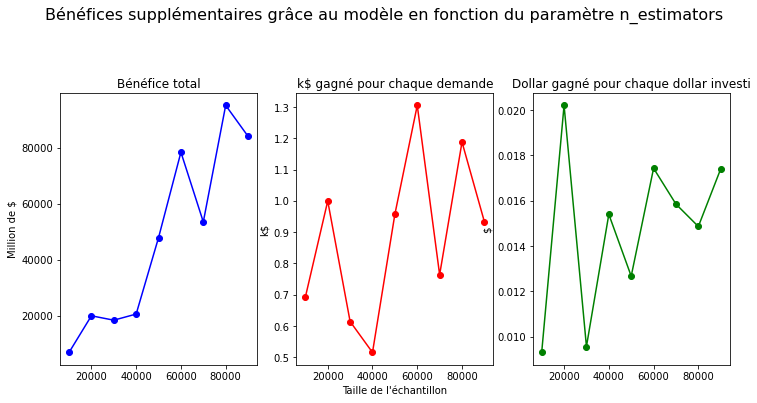

In [70]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Bénéfices supplémentaires grâce au modèle en fonction du paramètre n_estimators'
            , size=16, y=1.12)    
    
plt.rcParams["figure.figsize"] = (14,4)    
ax1.plot(range(10000, 100000, 10000), bene_somme_list, 'o-b')
ax1.set_title('Bénéfice total')
ax1.set_ylabel('Million de $')

ax2.plot(range(10000, 100000, 10000), eco_demandeur_list, 'o-r')
ax2.set_title('k$ gagné pour chaque demande')
ax2.set_ylabel('k$')
ax2.set_xlabel("Taille de l'échantillon")

ax3.plot(range(10000, 100000, 10000), eco_dollar_list, 'o-g')
ax3.set_title('Dollar gagné pour chaque dollar investi')
ax3.set_ylabel('$')

plt.show()

La taille de l'échantillon n'a pas d'influence sur les métriques comme le recall et la précision.
Par contre, elle a une forte influence sur le bénéfice supplémentaire par demande et par dollar investi. Il semblerait que la taille de l'échantillon optimale est de 30000.

## Apport des différentes bases de données et des nouvelles variables

### Application_train sans nouvelles variables

In [75]:
df_sans_nv = application_train_net()

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée


In [76]:
df_sans_nv.replace([np.inf, -np.inf], np.nan, inplace=True)

In [77]:
df_sans_nv=df_sans_nv.fillna(0)

In [78]:
df_sans_nv.shape

(307506, 56)

In [79]:
df_1 = df_sans_nv.sample(30000)

temps de calcul : 1.0 sec
Matrice de confusion
il y a : 
 3718 Vrais Négatifs (le prêt a été remboursé) 
 1790 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 221 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 271 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.68      0.79      5508
           1       0.13      0.55      0.21       492

    accuracy                           0.66      6000
   macro avg       0.54      0.61      0.50      6000
weighted avg       0.88      0.66      0.74      6000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  164901.322125 k$
la somme perdue sans modèle est  297385.272 k$
le bénéfice sans modèle est  -132484.0 k$
---------------------------------------

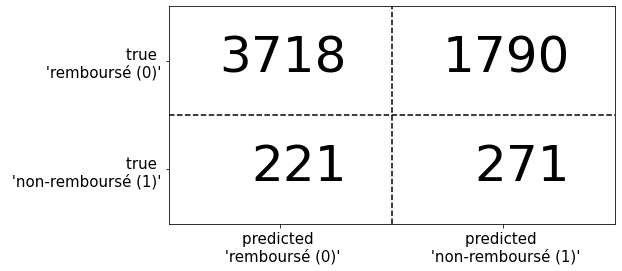

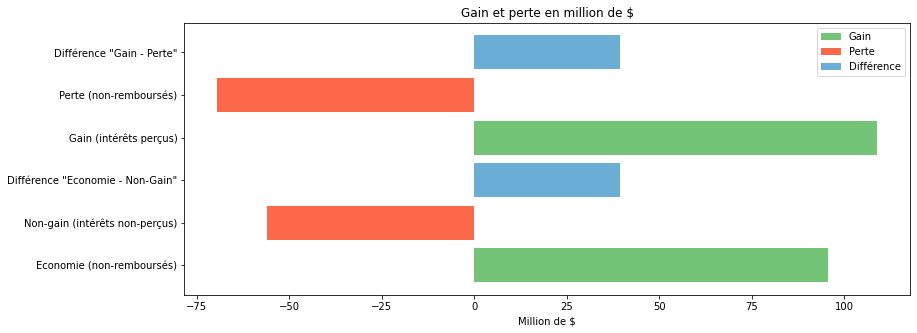

Arbre de décision : ROC AUC=0.636 Dummy : ROC AUC=0.501


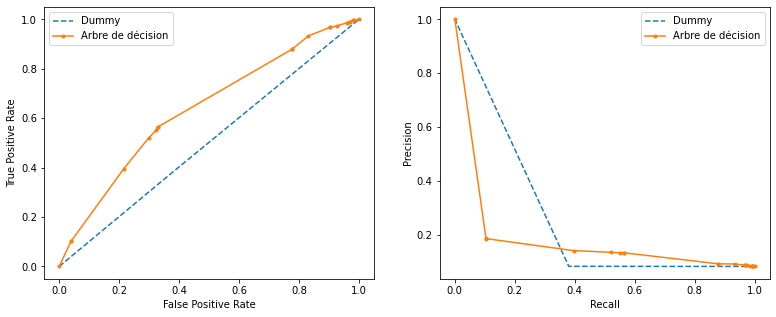

In [80]:
prediction, y_test, temps , lr_auc = add_(df_1)

### Modèle pour un nouveau client (application_train uniquement)

In [81]:
df_nv = fe(0)

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées
df shape: (307506, 71)


In [82]:
df_nv.replace([np.inf, -np.inf], np.nan, inplace=True)

In [83]:
df_nv=df_nv.fillna(0)

In [84]:
df_nv.shape

(307506, 71)

In [85]:
df_2 = df_nv.sample(30000)

temps de calcul : 1.1 sec
Matrice de confusion
il y a : 
 935 Vrais Négatifs (le prêt a été remboursé) 
 4575 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 45 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 445 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.17      0.29      5510
           1       0.09      0.91      0.16       490

    accuracy                           0.23      6000
   macro avg       0.52      0.54      0.22      6000
weighted avg       0.88      0.23      0.28      6000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  166739.57797500002 k$
la somme perdue sans modèle est  271497.906 k$
le bénéfice sans modèle est  -104758.0 k$
------------------------------------

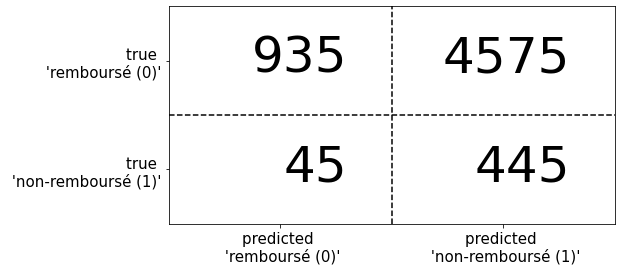

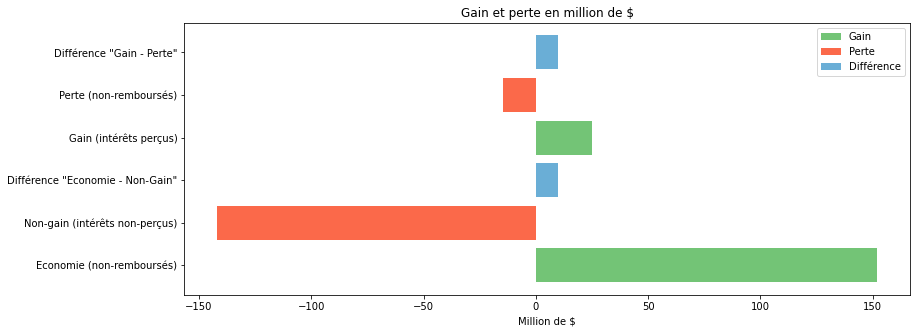

Arbre de décision : ROC AUC=0.551 Dummy : ROC AUC=0.507


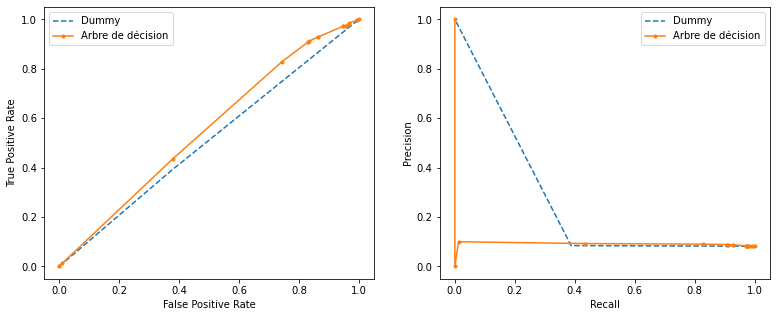

In [86]:
prediction, y_test, temps , lr_auc = add_(df_2)

### Modèle pour un client ayant déjà eu un accord de prêt (application_train et bureau)

In [87]:
df_bur = fe(1)

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées
la base de données bureau a été nettoyée et améliorée
les bases de données bureau et bureau_balance ont été assemblées
les bases de données bureau et bureau_balance ont été moyennées suivant SK_ID_CURR
Bureau df shape: (305811, 41)
df shape: (307506, 112)


In [88]:
df_bur.replace([np.inf, -np.inf], np.nan, inplace=True)

In [89]:
df_bur =df_bur.fillna(0)

In [90]:
df_bur.shape

(307506, 112)

In [91]:
df_3 = df_bur.sample(30000)

temps de calcul : 1.3 sec
Matrice de confusion
il y a : 
 3499 Vrais Négatifs (le prêt a été remboursé) 
 2018 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 213 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 270 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.63      0.76      5517
           1       0.12      0.56      0.19       483

    accuracy                           0.63      6000
   macro avg       0.53      0.60      0.48      6000
weighted avg       0.88      0.63      0.71      6000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  163277.943525 k$
la somme perdue sans modèle est  269991.2025 k$
le bénéfice sans modèle est  -106713.0 k$
--------------------------------------

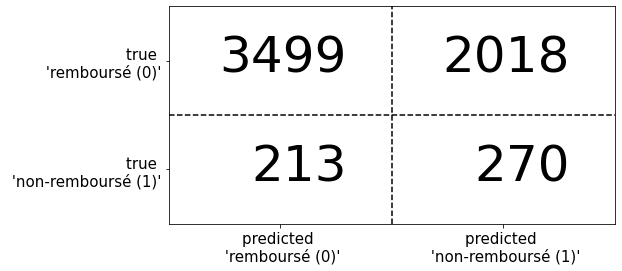

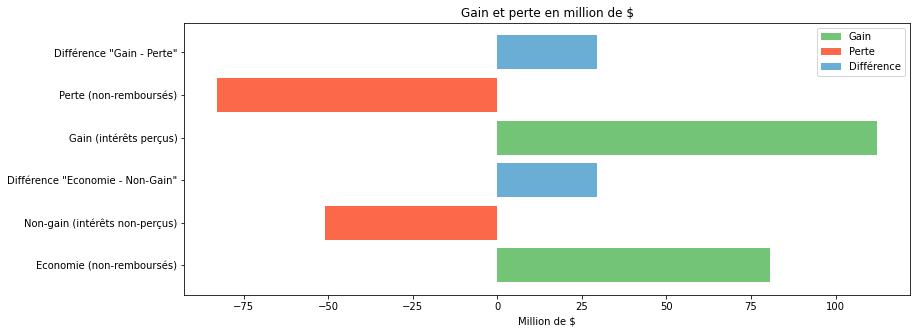

Arbre de décision : ROC AUC=0.623 Dummy : ROC AUC=0.502


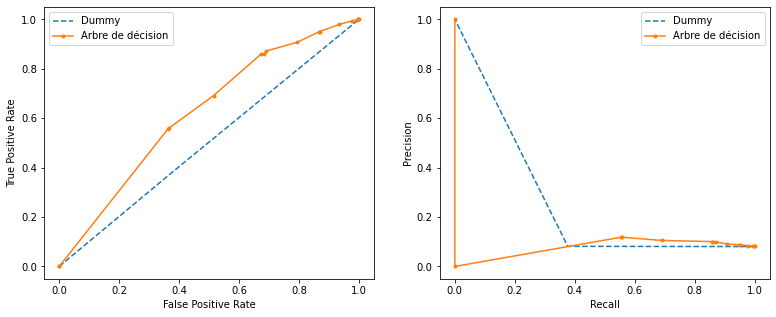

In [92]:
prediction, y_test, temps , lr_auc = add_(df_3)

### Modèle pour un client ayant déjà eu un accord de prêt (application_train, bureau et les 4 autres bases de données)

In [93]:
df_all = fe(2)

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées
la base de données bureau a été nettoyée et améliorée
les bases de données bureau et bureau_balance ont été assemblées
les bases de données bureau et bureau_balance ont été moyennées suivant SK_ID_CURR
Bureau df shape: (305811, 41)
Previous applications df shape: (338857, 240)
Pos-cash balance df shape: (337252, 18)
Installments payments df shape: (339587, 24)
Credit card balance df shape: (103558, 141)
df shape: (307506, 535)


In [94]:
df_all.replace([np.inf, -np.inf], np.nan, inplace=True)

In [95]:
df_all=df_all.fillna(0)

In [96]:
df_all.shape

(307506, 535)

In [97]:
df_4 = df_all.sample(30000)

temps de calcul : 8.2 sec
Matrice de confusion
il y a : 
 2242 Vrais Négatifs (le prêt a été remboursé) 
 3284 Faux Positifs (le prêt n'a pas été remboursé, le modèle dit que oui) 
 132 Faux Négatifs (le prêt a été remboursé, le modèle dit que non)
 342 Vrais Positifs (le prêt n'a pas été remboursé) 

-----------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.41      0.57      5526
           1       0.09      0.72      0.17       474

    accuracy                           0.43      6000
   macro avg       0.52      0.56      0.37      6000
weighted avg       0.88      0.43      0.54      6000

-----------------------------------------------------------------------------------------------
la somme gagnée sans modèle est  170328.852225 k$
la somme perdue sans modèle est  261280.2375 k$
le bénéfice sans modèle est  -90951.0 k$
---------------------------------------

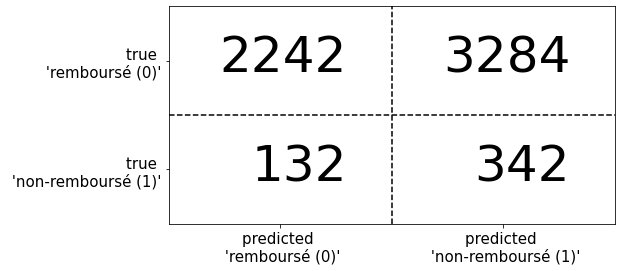

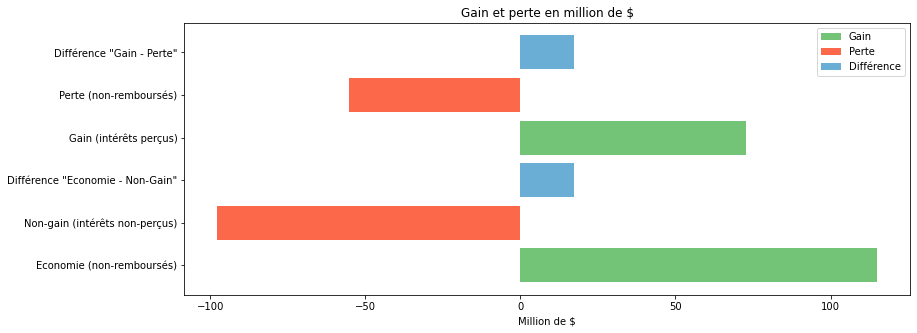

Arbre de décision : ROC AUC=0.602 Dummy : ROC AUC=0.515


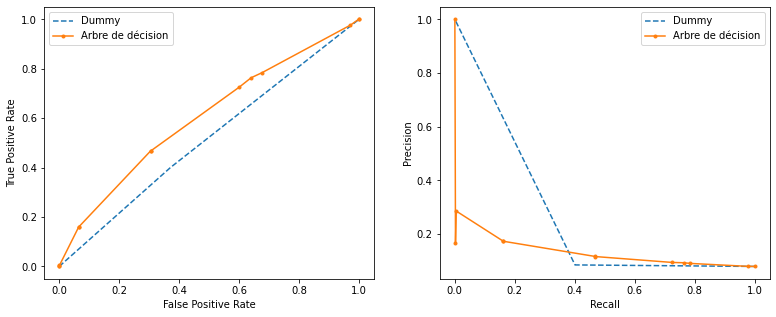

In [98]:
prediction, y_test, temps , lr_auc = add_(df_4)

Les bénéfices supplémentaires par dollar investi sont les suivants :
- 17\$ pour la base de données application_train uniquement, sans nouvelles variables (avec seulement le nettoyage)
- 20\$ pour la base de données application_train uniquement, avec nouvelles variables (et avec le nettoyage)
- 14\$ pour la base de données application_train et bureau, avec nouvelles variables (et avec le nettoyage)
- 9\$ pour l'intégralité des bases de données, avec nouvelles variables (et avec le nettoyage)

La base de données avec les nouvelles variables donnent les meilleurs résultats. Il n'est pas utile de passer du temps à faire des calculs avec les autres bases de données.